# Part A

## 1. Loading the data into pandas dataframes

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings_df = pd.read_csv('data/ratings.csv')
movies_df = pd.read_csv('data/movies.csv')


## 2. Report

In [27]:
unique_users = ratings_df['userId'].nunique()
unique_movies = ratings_df['movieId'].nunique()
num_ratings = ratings_df.shape[0]
sparsity = 1 - (num_ratings / (unique_users * unique_movies))

print("Number of unique users:", unique_users)
print("Number of unique movies:", unique_movies)
print("Number of ratings:", num_ratings)
print(f"Sparsity of the ratings matrix: {sparsity:.3%}")

Number of unique users: 610
Number of unique movies: 9724
Number of ratings: 100836
Sparsity of the ratings matrix: 98.300%


## 3. Building the user-item matrix

In [28]:
matrix = ratings_df.pivot_table(index='userId', columns='movieId', values='rating')

## 4. Plotting

### 4.1 Distribution of ratings

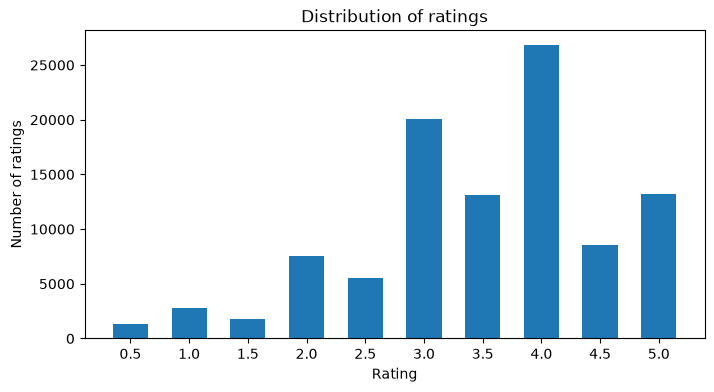

In [29]:
rating_counts = ratings_df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(rating_counts.index, rating_counts.values, width=0.3)
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Distribution of ratings")
plt.xticks(rating_counts.index)
plt.show()

### 4.2 Distribution of ratings per user

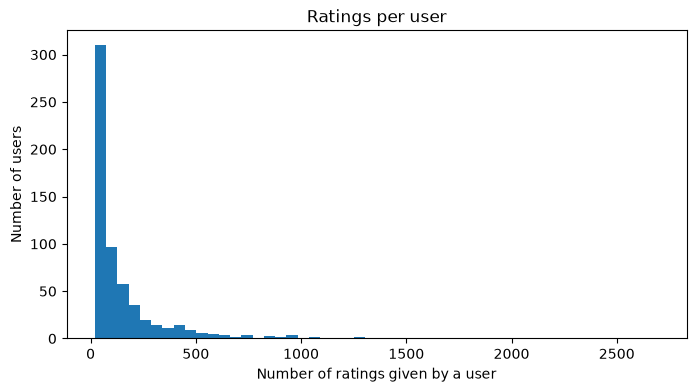

In [30]:
ratings_per_user = ratings_df.groupby('userId').size()

plt.figure(figsize=(8, 4))
plt.hist(ratings_per_user, bins=50)
plt.xlabel("Number of ratings given by a user")
plt.ylabel("Number of users")
plt.title("Ratings per user")
plt.show()

### Notes:-

1) In the distributions of ratings: 4.0 and 3.0 are the most common ratings, And that the whole numbers always beat the half-steps, People usually approximates to the whole number than using the halfs.

2) In the distribution of ratings per user: most users rated only a small number of movies, while a few users rated over 1000 movies, and one rated about 2700 movies. Since each user covers only a tiny fraction of the catalog, two users often share very few co-rated items.

# temp Part B

In [31]:
# temporary 
def get_co_rated(matrix, a, b, axis):
    if axis == "index":
        va, vb = matrix.loc[a].values, matrix.loc[b].values
    else:
        va, vb = matrix[a].values, matrix[b].values
    mask = ~np.isnan(va) & ~np.isnan(vb)
    return va[mask], vb[mask]

def cosine_similarity(vec1, vec2):
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

# Part C

## 9. Find k nearest users

In [32]:
def find_k_nearest_users(matrix,target_user,k,similarity_fn):
    scores = []
    for user in matrix.index:
        if user != target_user:
            vec1, vec2 = get_co_rated(matrix, target_user, user, axis="index")
            if (len(vec1) < 2):
                continue
            score = similarity_fn(vec1, vec2)
            if np.isnan(score):
                continue
            scores.append((user, score))

    return sorted(scores, key=lambda t: t[1], reverse=True)[:k]



## 10. Predict rating user based

In [33]:
def predict_rating_user_based(matrix,target_user,target_item,k,similarity_fn):
    if target_item not in matrix.columns:
        return None
    if target_user not in matrix.index:
        return None
    
    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)
    numerator = 0
    denominator = 0
    for user, score in neighbors:
        rating = matrix.loc[user, target_item]
        if np.isnan(rating):
            continue
        numerator += score * rating
        denominator += abs(score)
    if denominator == 0:
        return None
    return numerator / denominator


# Part D

## 11.1 Find k nearest items

In [34]:
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    scores = []
    for item in matrix.columns:
        if item != target_item:
            vec1, vec2 = get_co_rated(matrix, target_item, item, axis="columns")
            if (len(vec1) < 2):
                continue
            score = similarity_fn(vec1, vec2)
            if np.isnan(score):
                continue
            scores.append((item, score))
            
    return sorted(scores, key=lambda t: t[1], reverse=True)[:k]



## 11.2 Predict rating item based

In [37]:
def predict_rating_item_based(matrix,target_user,target_item,k,similarity_fn):
    if target_item not in matrix.columns:
        return None
    if target_user not in matrix.index:
        return None
    
    neighbors = find_k_nearest_items(matrix, target_item, k, similarity_fn)
    numerator = 0
    denominator = 0
    for item, score in neighbors:
        rating = matrix.loc[target_user, item]
        if np.isnan(rating):
            continue
        numerator += score * rating
        denominator += abs(score)
    if denominator == 0:
        return None
    return numerator / denominator


## 12. Explanation:-

We reused the same logic from part C, checking the same structure of the neighbor search (loop, skip himself, skip if fewer than 2 co-rated, applying similarity_fn) and using the same average formula.

We changed only that the loop runs over columns not rows (axis = "columns" instead axis = "index") and the rating lookups flips from (matrix.loc[neighbor, target_item]) to (matrix.loc[target_user, neighbor_item]).